In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator
import matplotlib.image as mpimg
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle

from highlight_text import ax_text, fig_text
from drawarrow import ax_arrow, fig_arrow
from pyfonts import load_google_font

from scipy.interpolate import PchipInterpolator

import os

In [2]:
# cleaned file
f_path = os.path.join(
    "..", "data", "clean",
    "launches_clean_plotting.csv"
)

data = pd.read_csv(f_path)

data.tail(1)

,Date,total_payloads,Overall,USA,Europe,Asia,Other
37,2025-12-24,1,434,233,139,41,21


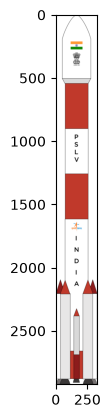

In [3]:
# load PSLV image
rocket_img = mpimg.imread(
    os.path.join(
        "..", "data", "image",
        "pslv.png"
    )
)

plt.imshow(rocket_img)

In [4]:
df = data.copy()

region_cols = ["USA", "Europe", "Asia", "Other"]

df_yearly = (
    df.assign(Date=pd.to_datetime(df["Date"]))
    .sort_values("Date")
    .set_index("Date")
    .resample("YE")[region_cols]
    .last()
    .ffill()
)

df_yearly["Overall"] = df_yearly[region_cols].sum(axis=1)

df_yearly["Year"] = df_yearly.index.year

df_yearly = df_yearly.reset_index(drop=True)

In [5]:
# df_yearly.to_csv(
#     os.path.join(
#     "..", "data", "clean",
#     "launches_clean_yearly_region.csv"
# ),
# index=False
# )

In [6]:
# regions to show
region_cols = ["USA", "Europe", "Asia", "Other"]

# dataset for plotting
df_plot = df_yearly.sort_values("Year").copy()

# actual non-smoothed data
x = df_plot["Year"].to_numpy(dtype=float)

y_usa = df_plot["USA"].to_numpy(dtype=float)
y_eu = df_plot["Europe"].to_numpy(dtype=float)
y_asia = df_plot["Asia"].to_numpy(dtype=float)
y_other = df_plot["Other"].to_numpy(dtype=float)

# smoothed data
x_sm = np.linspace(
    x.min(),
    x.max(),
    500
)

y_usa_sm = PchipInterpolator(x, y_usa)(x_sm)
y_eu_sm = PchipInterpolator(x, y_eu)(x_sm)
y_asia_sm = PchipInterpolator(x, y_asia)(x_sm)
y_other_sm = PchipInterpolator(x, y_other)(x_sm)

In [7]:
# milestones to annotate
y_min_milestone = 2010
df_mile = df_plot[df_plot["Year"]>=y_min_milestone]

milestone_years = list(range(y_min_milestone, 2026, 5))

milestone_totals = [
    df_mile[df_mile["Year"]==y]["Overall"].values[0] for y in milestone_years
]

In [67]:
# colors
# 00496FFF, #0F85A0FF, #EDD746FF, #ED8B00FF, #DD4124FF
#FCDD23FF, #F8B100FF, #CA697CFF, #AB74CFFF, #48439BFF, #03045e
"#042a2b","#5eb1bf","#cdedf6","#ef7b45","#d84727"
#4B6892FF, #F9E583FF, #FED43FFF, #F6BD28FF, #BE4C46FF
#2E0F16FF, #A32A2FFF, #EB9352FF, #F8E3DBFF, #91837DFF, #37947EFF
#4A3A3BFF, #984136FF, #C26A7AFF, #ECC0A1FF, #F0F0E4FF
#242424FF, #37253DFF, #852851FF, #E10131FF, #F6F4F5FF
#010101FF, #BA0C2FFF, #E03C31FF, #FFCD00FF


color_palette = {
    "background": "#FFF4E5",
    "text": "#25333B",
    "grid": "#D4C9BA",
    "usa": "#31576A",
    "europe": "#B34E4B",
    "asia": "#DB8950",
    "other": "#E8C96C",
    "pslv": "#7363A5",
    "other_vehicles": "#DDD4C9",
    "accent":"#D9603B"
}

region_colors = [
    color_palette["usa"],   # USA
    color_palette["europe"],   # Europe
    color_palette["asia"],   # Asia
    color_palette["other"]    # Other
]
# regions to plot
region_cols = ["USA", "Europe", "Asia", "Other"]

bold = load_google_font("Fira Sans", weight=500)
bold_italic = load_google_font("Fira Sans", weight=500, italic=True)
regular = load_google_font("Fira Sans", weight=300)
regular_italic = load_google_font("Fira Sans", weight=300, italic=True)
thin = load_google_font("Fira Sans", weight=100)
thin_italic = load_google_font("Fira Sans", italic=True, weight=200)




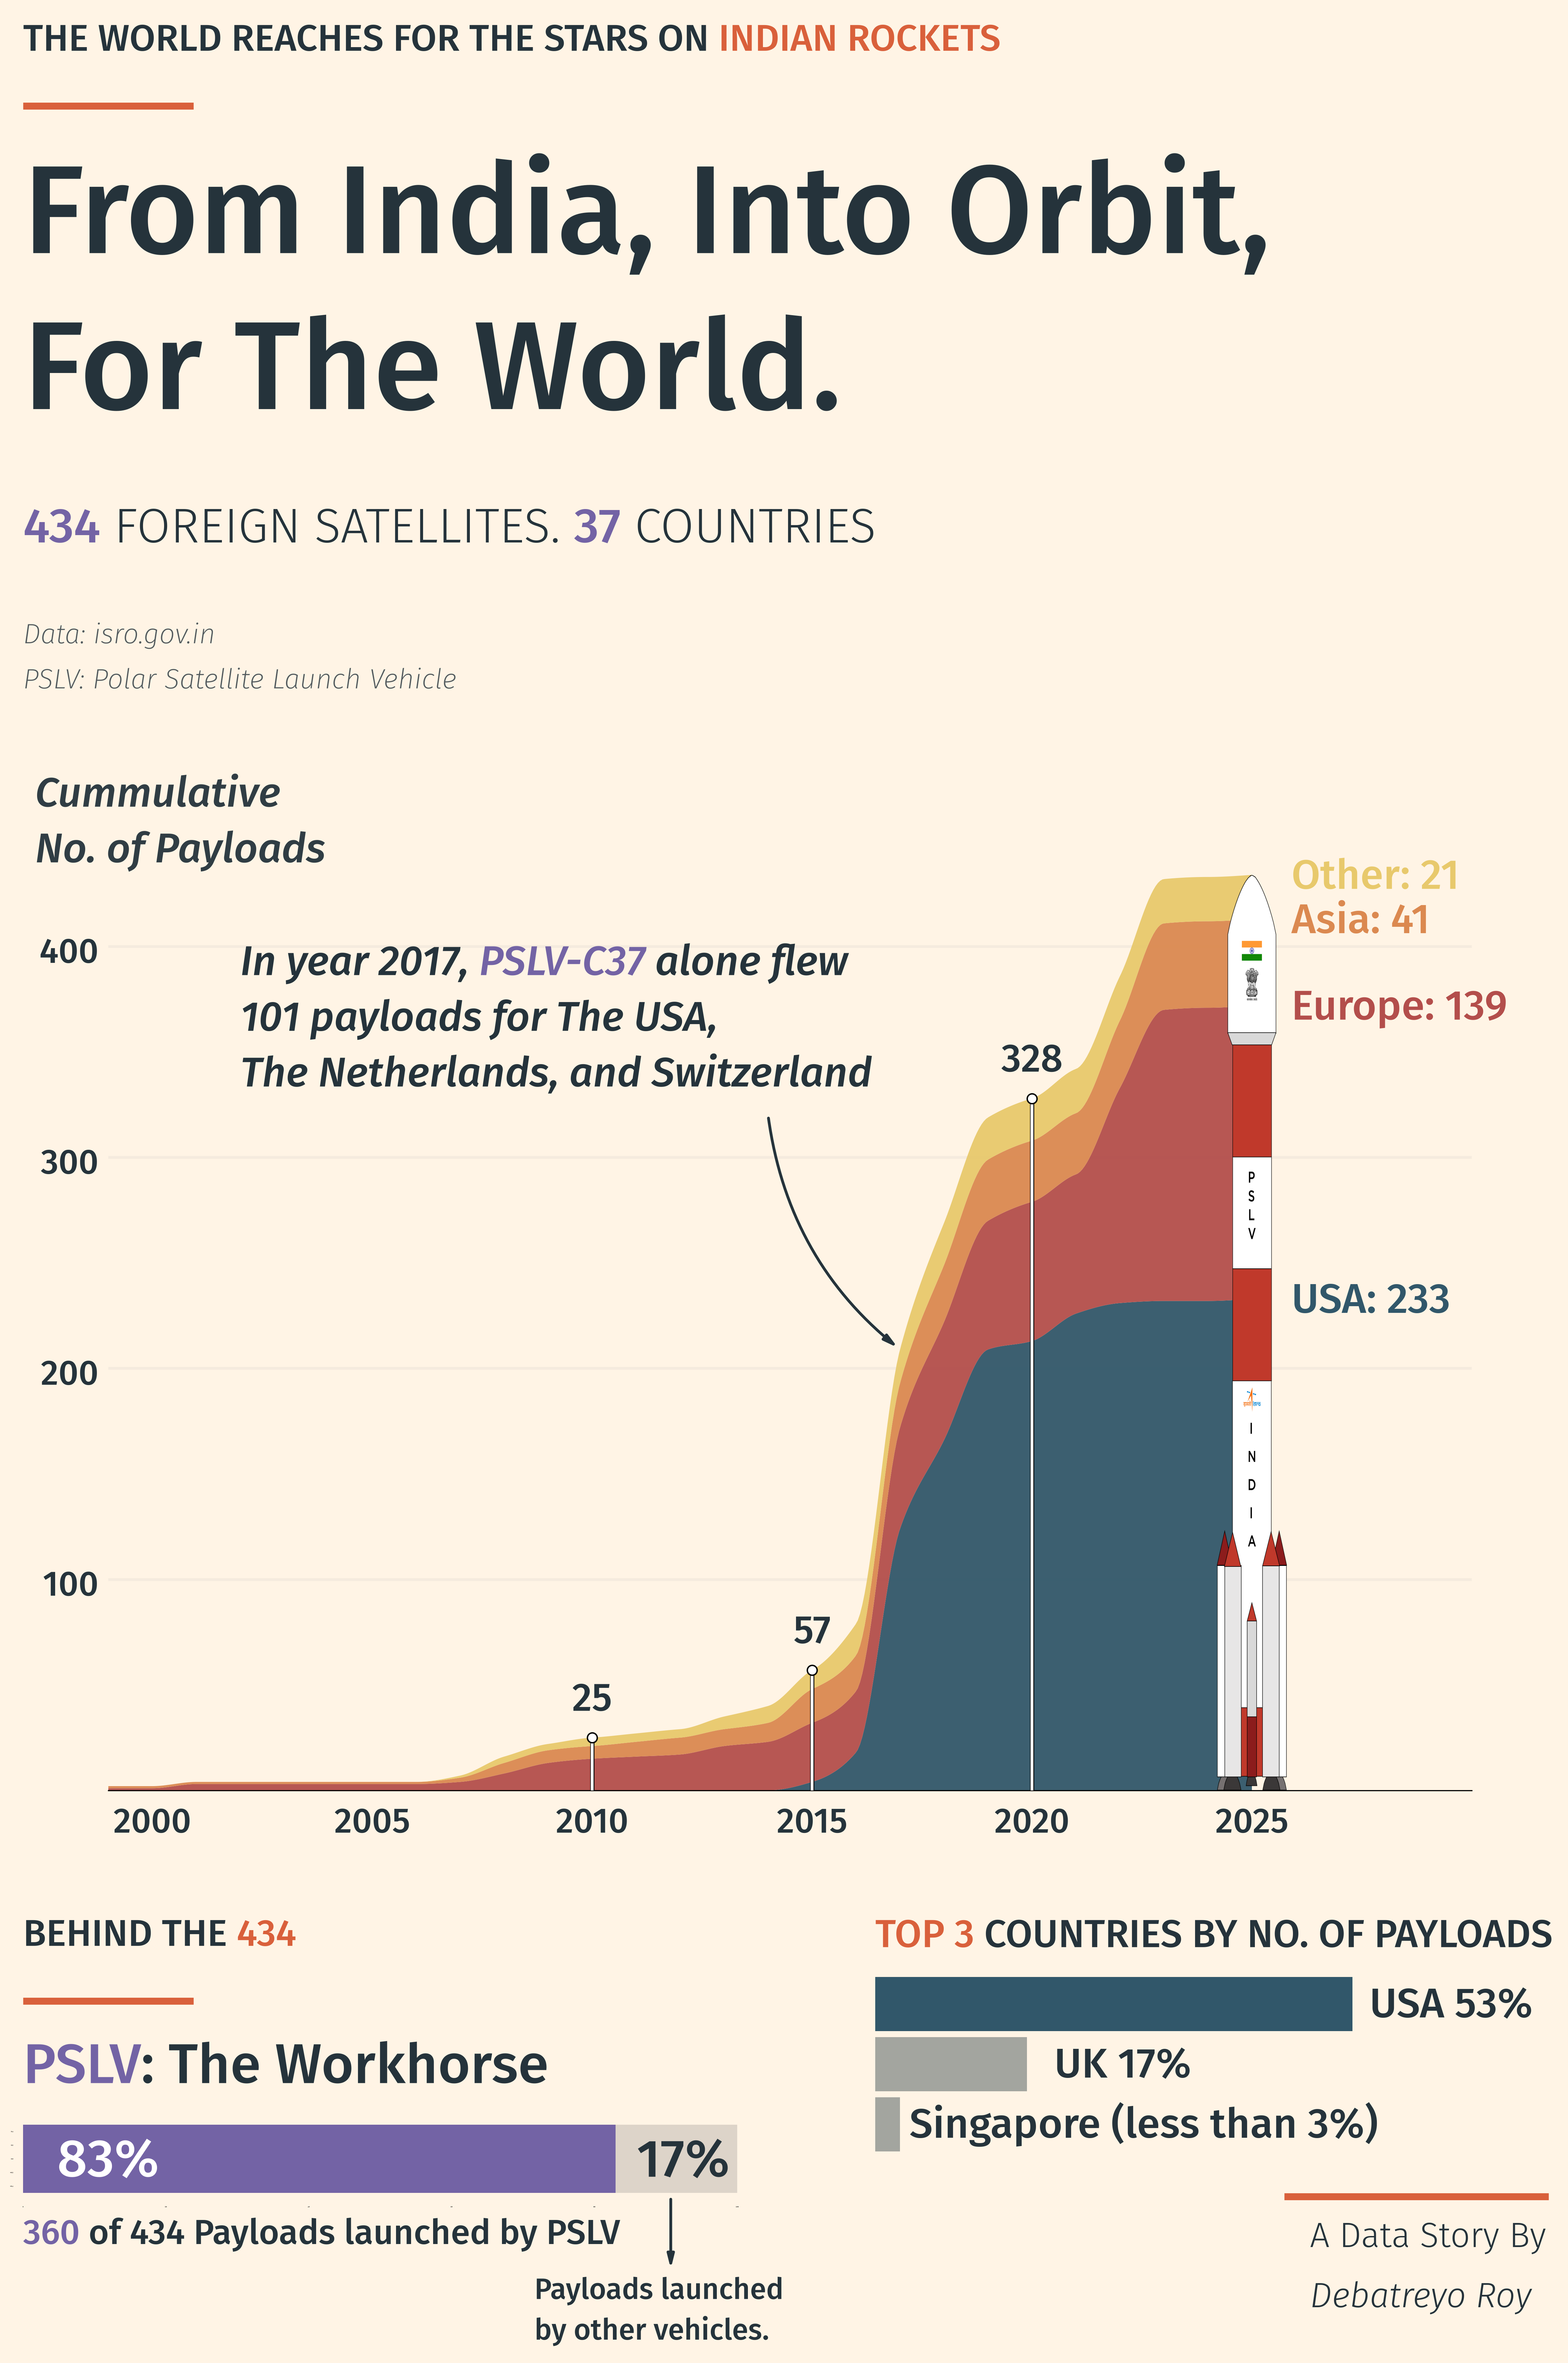

In [72]:
dpi = 300

fig, ax = plt.subplots(figsize=(17, 30), dpi=dpi)

fig.set_facecolor(color_palette["background"])
ax.set_facecolor(color_palette["background"])

fig.subplots_adjust(left=0.1, right=0.9, top=0.75, bottom=0.4)

# Title & Subtitles
# title
fig_text(
  x=0.05,
  y=0.99,
  s="THE WORLD REACHES FOR THE STARS ON <INDIAN ROCKETS>",
  size=27, color=color_palette["text"],
  font=bold,
  highlight_textprops=[
      dict(color=color_palette["accent"])
  ],
)

# short decorative underline
header_line = Line2D(
    [0.05, 0.15],
    [0.96, 0.96],
    color=color_palette["accent"],
    lw=5,
    solid_capstyle="butt",
    transform=fig.transFigure
)
fig.add_artist(header_line)

# Sub-title
fig_text(
  x=0.05,
  y=0.95,
  s="From India, Into Orbit,\nFor The World.",
  size=90, color=color_palette["text"],
  font=bold,
  highlight_textprops=[
      
  ],
)

# explanation
fig_text(
  x=0.05,
  y=0.83,
  s="<434> FOREIGN SATELLITES. <37> COUNTRIES",
  size=35, color=color_palette["text"],
  font=regular,
  highlight_textprops=[
      dict(color=color_palette["pslv"], font=bold),
      dict(color=color_palette["pslv"], font=bold)
  ],
)

# data source
fig_text(
  x=0.05,
  y=0.79,
  s="Data: isro.gov.in",
  size=20,
  font=thin_italic,
  color=color_palette["text"],
  alpha=0.8
)
fig_text(
  x=0.05,
  y=0.775,
  s="PSLV: Polar Satellite Launch Vehicle",
  size=20,
  font=thin_italic,
  color=color_palette["text"],
  alpha=0.8
)


###################################

ax.stackplot(
    x_sm,
    y_usa_sm,
    y_eu_sm,
    y_asia_sm,
    y_other_sm,
    labels=region_cols,
    colors=region_colors,
    alpha=0.95
)

final_values = np.array([
    y_usa[-1],
    y_eu[-1],
    y_asia[-1],
    y_other[-1]
])

cumulative_values = np.cumsum(final_values)

bottom_values = np.concatenate((
    [0],
    cumulative_values[:-1]
))

end_values = np.cumsum(final_values)

for region, color, end, value in zip(
    region_cols,
    region_colors,
    end_values,
    final_values
):

    ax.text(
        x.max() + 0.9,
        end,
        f"{region}: {int(value):,}",
        fontsize=30,
        font=bold,
        color=color,
        va="center"
    )


overall_total = int(final_values.sum())

ax.xaxis.set_major_locator(
    MultipleLocator(5)
)

ax.set_xlim(
    x.min(),
    x.max() + 5
)

ax.set_ylim(
    0,
    overall_total * 1.15
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)

ax.grid(
    axis="y",
    alpha=0.12,
    linewidth=2
)

ax.set_axisbelow(True)

ax.tick_params(
    axis="both",
    labelsize=25,
    width=0,
    
)
ax.set_xticks(
    ticks=[2000, 2005, 2010, 2015, 2020, 2025],
    labels=["2000", "2005", "2010", "2015", "2020", "2025"],
    font=bold, size=25, color=color_palette["text"]
)
ax.set_yticks(
    ticks=[100, 200, 300, 400],
    labels=["100", "200", "300", "400"],
    font=bold, size=25, color=color_palette["text"]
)
fig_text(
  x=0.057,
  y=0.74,
  s="Cummulative\nNo. of Payloads",
  size=30,
  font=bold_italic,
  color=color_palette["text"],
  alpha=0.95
)


##################################################
# PSLV images annotation                         #
##################################################

# Width of rocket in x-axis units (years)
rocket_width = {
    2010:0.2,
    2015:0.3,
    2020:1.2,
    2025:1.6
}

# Preserve existing axis limits
x_limits = ax.get_xlim()
y_limits = ax.get_ylim()

# Draw rockets at milestone years
y_min, y_max = ax.get_ylim()
for year, total in zip(milestone_years, milestone_totals):
    if year != 2025:
        ax_text(
            s=str(int(total)), x=year, y=total+30,
            font=bold, size=28, ha="center", color=color_palette["text"]
        )
    if year == 2025:
        ax.imshow(
            rocket_img,
            extent=[
                year - rocket_width.get(year, 2) / 2,
                year + rocket_width.get(year, 2) / 2,
                0,
                total
            ],
            aspect="auto",
            interpolation="lanczos",
            zorder=4
        )
    else:
        ymax_axes = (total - y_min) / (y_max - y_min)
        ax.axvline(x=year, ymax=ymax_axes, color="black", linewidth=3, zorder=2)
        ax.axvline(x=year, ymax=ymax_axes, color="white", linewidth=2, zorder=5)
        ax.scatter(x=[year], y=[total], s=50, marker="o", facecolor="white", edgecolor="black", zorder=10)

# Restore axis limits
ax.set_xlim(x_limits)
ax.set_ylim(y_limits)

# 2017 year annotation
ax_arrow(
    tail_position=[2014, 320], head_position=[2017, 209],
    color=color_palette["text"], head_width=2, width=2,
    radius=0.2
)
ax_text(
    x=2002, y=405,
    s="In year 2017, <PSLV-C37> alone flew\n101 payloads for The USA,\nThe Netherlands, and Switzerland",
    font=bold_italic, size=30, color=color_palette["text"],
    highlight_textprops=[
        dict(color=color_palette["pslv"])
    ]
)

####################################
# Bottom portion elements
fig_text(
  x=0.05,
  y=0.36,
  s="BEHIND THE <434>",
  size=27, color=color_palette["text"],
  font=bold,
  highlight_textprops=[
      dict(color=color_palette["accent"])
  ],
)
# short decorative underline
header_line_bottom = Line2D(
    [0.05, 0.15],
    [0.33, 0.33],
    color=color_palette["accent"],
    lw=5,
    solid_capstyle="butt",
    transform=fig.transFigure
)
fig.add_artist(header_line_bottom)
fig_text(
  x=0.05,
  y=0.32,
  s="<PSLV>: The Workhorse",
  size=40, color=color_palette["text"],
  font=bold,
  highlight_textprops=[
      dict(color=color_palette["pslv"])
  ],
)


# 4. Create separate axes for progress bar
ax_pslv = fig.add_axes([
    0.05,   # left
    0.265,  # bottom
    0.44,   # width
    0.025   # height
])
ax_pslv.set_facecolor(color_palette["background"])
ax_pslv.spines[["top", "bottom", "left", "right"]].set_visible(0)
ax_pslv.tick_params(
    axis="both",
    labelsize=0, width=0
)

# PSLV segment
pslv_total = 360
overall_total = 434
other_total = overall_total - pslv_total

pslv_pct = (pslv_total / overall_total) * 100
other_pct = (other_total / overall_total) * 100

ax_pslv.barh(
    y=0,
    width=pslv_pct,
    left=0,
    height=1,
    color=color_palette["pslv"],
    edgecolor="none"
)


# Other launch vehicles segment
ax_pslv.barh(
    y=0,
    width=other_pct,
    left=pslv_pct,
    height=1,
    color=color_palette["other_vehicles"],
    edgecolor="none"
)

fig_text(
  x=0.07,
  y=0.288,
  s="83%",
  size=38, color="white",
  font=bold,
  highlight_textprops=[
      
  ],
)
fig_text(
  x=0.05,
  y=0.26,
  s="<360> of 434 Payloads launched by PSLV",
  size=25, color=color_palette["text"],
  font=bold,
  highlight_textprops=[
      dict(color=color_palette["pslv"])
  ],
)
fig_text(
  x=0.41,
  y=0.288,
  s="17%",
  size=38, color=color_palette["text"],
  font=bold,
  highlight_textprops=[
      
  ],
)
fig_text(
  x=0.35,
  y=0.24,
  s="Payloads launched\nby other vehicles.",
  size=21, color=color_palette["text"],
  font=bold,
  highlight_textprops=[
      
  ],
)
fig_arrow(
    tail_position=[0.43, 0.265],
    head_position=[0.43, 0.24],
    width=2, color=color_palette["text"],
    head_width=2
)

# -------------------------------------------
# TOP 3 COUNTRIES BY PAYLOADS
# -------------------------------------------

# Data
country_payloads = {
    "USA": 233,
    "UK": 74,
    "Singapore": 12
}
country_names = list(country_payloads.keys())
country_values = list(country_payloads.values())

fig_text(
  x=0.55,
  y=0.36,
  s="<TOP 3> COUNTRIES BY NO. OF PAYLOADS",
  size=28, color=color_palette["text"],
  font=bold,
  highlight_textprops=[
      dict(color=color_palette["accent"])
  ],
)

max_value = 233
other_country_color = "#A3A59F"
bar_x = 0.55
bar_y = 0.32
bar_max_width = 0.28
bar_height = 0.018

# 1. Data USA
usa_value = 233
usa_color = color_palette["usa"]

bar_width_usa = (usa_value / max_value) * bar_max_width
usa_bar = Rectangle(
    xy=(bar_x, bar_y),
    width=bar_width_usa,
    height=bar_height,
    facecolor=usa_color,
    edgecolor="none",
    transform=fig.transFigure,
    zorder=2
)
fig.add_artist(usa_bar)
fig_text(
  x=0.84,
  y=0.3375,
  s="USA <53%>",
  size=30, color=color_palette["text"],
  font=bold,
    zorder=100,
  highlight_textprops=[
      dict(color=color_palette["text"])
  ],
)

# 2. Data UK
uk_value = 74
uk_color = other_country_color

bar_width_uk = (uk_value / max_value) * bar_max_width
uk_bar = Rectangle(
    xy=(bar_x, bar_y-0.02),
    width=bar_width_uk,
    height=bar_height,
    facecolor=uk_color,
    edgecolor="none",
    transform=fig.transFigure,
    zorder=2
)
fig.add_artist(uk_bar)
fig_text(
  x=0.655,
  y=0.3375-0.02,
  s="UK <17%>",
  size=30, color=color_palette["text"],
  font=bold,
    zorder=100,
  highlight_textprops=[
      dict(color=color_palette["text"])
  ],
)

# 3. Data Singapore
singapore_value = 12
singapore_color = other_country_color

bar_width_singapore = (singapore_value / max_value) * bar_max_width
singapore_bar = Rectangle(
    xy=(bar_x, bar_y-0.02*2),
    width=bar_width_singapore,
    height=bar_height,
    facecolor=singapore_color,
    edgecolor="none",
    transform=fig.transFigure,
    zorder=2
)
fig.add_artist(singapore_bar)
fig_text(
  x=0.57,
  y=0.3375-0.02*2,
  s="Singapore (less than 3%)",
  size=30, color=color_palette["text"],
  font=bold,
    zorder=100,
  highlight_textprops=[
      
  ],
)

############################################
# short decorative underline
header_line_sign = Line2D(
    [0.79, 0.945],
    [0.265, 0.265],
    color=color_palette["accent"],
    lw=5,
    solid_capstyle="butt",
    transform=fig.transFigure
)
fig.add_artist(header_line_sign)

fig_text(
    x=0.805, y=0.259,
    s="A Data Story By",
    size=25, font=regular,
    color=color_palette["text"]
)
fig_text(
    x=0.805, y=0.239,
    s="Debatreyo Roy",
    size=25, font=regular_italic,
    color=color_palette["text"]
)


############################################


save_path = os.path.join(
    "..", "viz",
    "test_sm_pslv_bottom_4.jpeg"
)

plt.savefig(save_path, dpi=dpi, bbox_inches="tight", pad_inches=2)